# Predicting Globular-Cluster RGB Ridgelines from Metallicity and Reddening

**Forward model for HUGS RGB fiducials, and its inversion to [Fe/H]**

*Data: HUGS ridgelines (F275W, F336W, F438W, F606W, F814W), Harris (2010) [Fe/H] and E(B−V), Kruijssen et al. ages, GC distances.*

> The first three code cells (setup, data, computation) are collapsed. They do all the fitting. Every figure and number below is computed from them, so rerunning the notebook refreshes the text too.

## The idea in plain words

**What are we looking at?** Globular clusters are huge, ancient balls of stars. If you plot every star's *brightness* against its *colour*, the red-giant stars line up along a curve, like a fingerprint. We call that curve the **ridgeline**. Every cluster has its own ridgeline, and we measured it in many pairs of colours (10 pairs) using the Hubble Space Telescope.

**The question.** A cluster's fingerprint depends mostly on two things: how rich the stars are in heavy elements (**metallicity**, written [Fe/H]), and how much interstellar **dust** sits between us and the cluster (which makes it look redder, written E(B−V)). So:

* **Forward:** if we know a cluster's metallicity and dust, can we **predict its fingerprint**?
* **Reverse:** if we only see a cluster's fingerprint, can we **work out its metallicity**?

**Why it works with so little data.** The fingerprint is a long list of numbers (80 per cluster), but they all move together, a bit like the many pixels of a face that all change when someone smiles. Just a few "dials" (we use 2 or 3) describe almost everything, and we learn how the dials depend on metallicity and dust.

**How we avoid fooling ourselves.** Every score below is an *exam on a cluster the model has never seen*: we remove one cluster, train on the rest, and predict the one left out, then repeat for every cluster.

| Term | Meaning |
|---|---|
| **Ridgeline** | The line the cluster's red-giant stars follow in a colour–brightness plot |
| **[Fe/H] (metallicity)** | How rich the stars are in iron and heavier elements. More negative = poorer. The Sun is 0. |
| **E(B−V) (reddening)** | How much dust dims and reddens the light on its way to us |
| **mag** | Magnitude, the astronomers' unit of brightness or colour difference. A smaller number is brighter. |
| **dex** | A factor of 10 in abundance: 0.1 dex is about a 26% difference |
| **RMSE** | The typical size of an error. Smaller is better. |
| **PCA** | A method that squeezes a long list of correlated numbers into a few "dials" |


In [1]:
import os, re, io, zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display

from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVR
from sklearn.model_selection import LeaveOneOut, GridSearchCV, cross_val_predict

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'axes.titlesize': 11, 'axes.labelsize': 11})

PROJECT_DIR = Path().resolve()
while PROJECT_DIR.name != 'spectroscopy-regression' and PROJECT_DIR != PROJECT_DIR.parent:
    PROJECT_DIR = PROJECT_DIR.parent
os.chdir(PROJECT_DIR)

GRID = np.arange(-0.75, 1.01, 0.25)           # M_F814W bins shared by all clusters
SHOW = ['F275W-F336W', 'F336W-F438W', 'F438W-F814W', 'F606W-F814W']
MLAB = r'$M_{\mathrm{F814W}}$ [mag]'
nice = lambda c: c.replace('-', '\u2212')

In [2]:
labels = pd.read_csv('data/GC_metallicity_harris.csv').set_index('NGC')['Fe/H_harris']
ebv_all = pd.read_csv('data/GC_reddening_harris.csv').set_index('NGC')['EBV']

ridges = {}
with zipfile.ZipFile('data/GC Ridgelines.zip') as zf:
    for name in zf.namelist():
        m = re.search(r'NGC(\d+)_F814W_ridge\.csv$', name)
        if not m:
            continue
        d = pd.read_csv(io.BytesIO(zf.read(name)))
        d = d[d['low_conf'].astype(str) == 'False'].drop(columns='low_conf').dropna()
        if len(d) >= 2:
            ridges[int(m.group(1))] = d.sort_values('F814W_abs')

COLORS = [c for c in next(iter(ridges.values())).columns if '-' in c]

def ridge_vector(d):
    x = d['F814W_abs'].to_numpy()
    if GRID.min() < x.min() or GRID.max() > x.max():
        return None
    return np.concatenate([np.interp(GRID, x, d[c].to_numpy()) for c in COLORS])

Y = pd.DataFrame({n: ridge_vector(d) for n, d in ridges.items() if ridge_vector(d) is not None}).T
Y.columns = pd.MultiIndex.from_product([COLORS, GRID], names=['color', 'M_F814W'])
feh, ebv = labels.loc[Y.index], ebv_all.loc[Y.index]

ages = (pd.read_csv('data/NGC_combi.csv').rename(columns=str.strip)
        .assign(NGC=lambda d: pd.to_numeric(d['NGC'].astype(str).str.strip(), errors='coerce'))
        .groupby('NGC')['age_Kruijssen'].median())
age = ages.reindex(Y.index)
Yv, fv, ev, av = Y.to_numpy(), feh.to_numpy(), ebv.to_numpy(), age.to_numpy()
has_age = ~np.isnan(av)

In [3]:
class ForwardModel:
    """PCA(k) on ridge vectors + polynomial regression from inputs to PCA scores."""
    def __init__(self, k=3, deg=2):
        self.k, self.deg = k, deg
    def fit(self, X, Y):
        self.scaler = StandardScaler().fit(X)
        Z = Y
        if self.k is not None:
            self.pca = PCA(n_components=self.k).fit(Y)
            Z = self.pca.transform(Y)
        self.reg = make_pipeline(PolynomialFeatures(self.deg), LinearRegression()).fit(self.scaler.transform(X), Z)
        return self
    def predict(self, X):
        Z = self.reg.predict(self.scaler.transform(X))
        return Z if self.k is None else self.pca.inverse_transform(Z)

def loo_forward(make, X, Y):
    P = np.zeros_like(Y, dtype=float)
    idx = np.arange(len(Y))
    for i in idx:
        tr = idx != i
        P[i] = make().fit(X[tr], Y[tr]).predict(X[[i]])[0]
    return P

rmse = lambda P, T: float(np.sqrt(np.mean((P - T) ** 2)))
loo_mean = lambda T: np.array([T[np.arange(len(T)) != i].mean(0) for i in range(len(T))])

# ---- PCA of the full sample
pca_full = PCA().fit(Yv)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)
scores = pca_full.transform(Yv)

# ---- forward model: which inputs matter?
INPUTS = {'[Fe/H]': np.c_[fv], 'E(B\u2212V)': np.c_[ev], '[Fe/H] + E(B\u2212V)': np.c_[fv, ev]}
baseline = loo_mean(Yv)
rows, loo_preds = [], {}
for iname, X in INPUTS.items():
    for k in [None, 2, 3, 4]:
        for deg in [1, 2, 3]:
            P = loo_forward(lambda: ForwardModel(k, deg), X, Yv)
            name = f'{"per-bin" if k is None else f"PCA{k}"} + poly{deg}'
            rows.append(dict(inputs=iname, model=name, k=k, deg=deg, RMSE_mag=rmse(P, Yv)))
            loo_preds[(iname, name)] = P
res = pd.DataFrame(rows)
BEST_IN = '[Fe/H] + E(B\u2212V)'
sub = res[(res.inputs == BEST_IN) & res.model.str.startswith('PCA')]
best = sub.loc[sub.RMSE_mag.idxmin()]
K_BEST, DEG_BEST, BEST_NAME = int(best.k), int(best.deg), best.model
P_best = loo_preds[(BEST_IN, BEST_NAME)]
fe_only = res[(res.inputs == '[Fe/H]') & res.model.str.startswith('PCA')]
FE_NAME = fe_only.loc[fe_only.RMSE_mag.idxmin(), 'model']
P_fe = loo_preds[('[Fe/H]', FE_NAME)]
ebv_only = res[(res.inputs == 'E(B\u2212V)') & res.model.str.startswith('PCA')]
RMSE = dict(mean=rmse(baseline, Yv), fe=rmse(P_fe, Yv), ebv=float(ebv_only.RMSE_mag.min()), both=rmse(P_best, Yv))

# ---- age test (clusters with an age)
Ys = Yv[has_age]
age_rows = [dict(inputs='mean ridge', RMSE_mag=rmse(loo_mean(Ys), Ys))]
age_preds = {}
for iname, X in {'[Fe/H] + E(B\u2212V)': np.c_[fv, ev][has_age], '[Fe/H] + E(B\u2212V) + age': np.c_[fv, ev, av][has_age]}.items():
    for k, deg in [(2, 1), (2, 2), (3, 2)]:
        P = loo_forward(lambda: ForwardModel(k, deg), X, Ys)
        age_rows.append(dict(inputs=iname, model=f'PCA{k} + poly{deg}', RMSE_mag=rmse(P, Ys)))
        age_preds[(iname, f'PCA{k} + poly{deg}')] = P
age_res = pd.DataFrame(age_rows)
a_no = age_res[age_res.inputs == '[Fe/H] + E(B\u2212V)'].RMSE_mag.min()
a_yes = age_res[age_res.inputs == '[Fe/H] + E(B\u2212V) + age'].RMSE_mag.min()

# ---- inversion: ridge -> [Fe/H]
xs = np.linspace(-2.7, 0.0, 541)
idx = np.arange(len(Yv))
inv, inv_sd = np.zeros(len(Yv)), np.zeros(len(Yv))
Xin = INPUTS[BEST_IN]
for i in idx:
    tr = idx != i
    m = ForwardModel(K_BEST, DEG_BEST).fit(Xin[tr], Yv[tr])
    sd = (Yv[tr] - m.predict(Xin[tr])).std(0, ddof=K_BEST + 1) + 1e-3
    chi2 = (((m.predict(np.c_[xs, np.full_like(xs, ev[i])]) - Yv[i]) / sd) ** 2).sum(1)
    inv[i] = xs[chi2.argmin()]
    ok = xs[chi2 <= chi2.min() + max(chi2.min() / (Yv.shape[1] - K_BEST), 1.0)]
    inv_sd[i] = (ok.max() - ok.min()) / 2

ridge_m = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 40)))
svr_m = make_pipeline(StandardScaler(), GridSearchCV(SVR(), {'C': [1, 10, 100], 'gamma': ['scale', 1e-3, 1e-2], 'epsilon': [0.02, 0.1]}, cv=5))
direct = {'Direct ridge regression': np.ravel(cross_val_predict(ridge_m, Yv, fv, cv=LeaveOneOut())),
          'Direct SVR (RBF)': np.ravel(cross_val_predict(svr_m, Yv, fv, cv=LeaveOneOut()))}
estimators = {'Inverted forward model (E(B\u2212V) given)': inv, **direct}
inv_rmse = {k: rmse(v, fv) for k, v in estimators.items()}
inv_rmse_mean = float(fv.std())

In [4]:
display(Markdown(f"""
## Summary of findings

**In one sentence:** knowing a cluster's metallicity *and* its dust is enough to predict its red-giant ridgeline to within about {RMSE['both']:.2f} magnitudes, and dust matters as much as metallicity. Going the other way, the ridgeline gives a cluster's metallicity to about {inv_rmse['Direct SVR (RBF)']:.2f} dex.

| | |
|---|---|
| **Sample** | {len(Y)} Milky Way globular clusters with HUGS RGB ridgelines in all of F275W, F336W, F438W, F606W, F814W (10 colours each), sampled at {len(GRID)} absolute-magnitude bins, {Y.shape[1]} numbers per cluster |
| **Dimensionality** | The ridge vector is almost 1-D: PC1 holds **{pca_full.explained_variance_ratio_[0]*100:.1f}%** of the variance, PC1+PC2 **{cum_var[1]*100:.1f}%** |
| **What sets the ridges** | PC1 correlates equally with [Fe/H] (r = {np.corrcoef(scores[:,0], fv)[0,1]:+.2f}) and with reddening E(B\u2212V) (r = {np.corrcoef(scores[:,0], ev)[0,1]:+.2f}); the two are themselves correlated (r = {np.corrcoef(fv, ev)[0,1]:+.2f}) |
| **Forward model, hold-one-cluster-out error on ridge colours** | mean ridge **{RMSE['mean']:.2f}** mag \u2192 [Fe/H] only **{RMSE['fe']:.2f}** \u2192 E(B\u2212V) only **{RMSE['ebv']:.2f}** \u2192 [Fe/H] + E(B\u2212V) **{RMSE['both']:.2f}** mag |
| **Age** | on the {has_age.sum()} clusters with an age: {a_no:.3f} \u2192 {a_yes:.3f} mag when age is added (small, small sample) |
| **Inversion to [Fe/H]** | forward-model inversion **{inv_rmse['Inverted forward model (E(B\u2212V) given)']:.2f}** dex, direct ridge **{inv_rmse['Direct ridge regression']:.2f}** dex, direct SVR **{inv_rmse['Direct SVR (RBF)']:.2f}** dex, versus {inv_rmse_mean:.2f} dex for predicting the mean |

**Take-away.** A two-parameter model ([Fe/H], E(B\u2212V)) with a 2\u20133 component PCA reproduces held-out ridgelines to about {RMSE['both']:.2f} mag. Dust is a first-order effect in the (undereddened) HUGS colours and must be modelled; [Fe/H] alone leaves most of the cluster-to-cluster variation unexplained.
"""))


## Summary of findings

**In one sentence:** knowing a cluster's metallicity *and* its dust is enough to predict its red-giant ridgeline to within about 0.17 magnitudes, and dust matters as much as metallicity. Going the other way, the ridgeline gives a cluster's metallicity to about 0.14 dex.

| | |
|---|---|
| **Sample** | 54 Milky Way globular clusters with HUGS RGB ridgelines in all of F275W, F336W, F438W, F606W, F814W (10 colours each), sampled at 8 absolute-magnitude bins, 80 numbers per cluster |
| **Dimensionality** | The ridge vector is almost 1-D: PC1 holds **98.8%** of the variance, PC1+PC2 **99.8%** |
| **What sets the ridges** | PC1 correlates equally with [Fe/H] (r = +0.83) and with reddening E(B−V) (r = +0.83); the two are themselves correlated (r = +0.46) |
| **Forward model, hold-one-cluster-out error on ridge colours** | mean ridge **0.86** mag → [Fe/H] only **0.43** → E(B−V) only **0.49** → [Fe/H] + E(B−V) **0.17** mag |
| **Age** | on the 25 clusters with an age: 0.142 → 0.131 mag when age is added (small, small sample) |
| **Inversion to [Fe/H]** | forward-model inversion **0.18** dex, direct ridge **0.18** dex, direct SVR **0.14** dex, versus 0.54 dex for predicting the mean |

**Take-away.** A two-parameter model ([Fe/H], E(B−V)) with a 2–3 component PCA reproduces held-out ridgelines to about 0.17 mag. Dust is a first-order effect in the (undereddened) HUGS colours and must be modelled; [Fe/H] alone leaves most of the cluster-to-cluster variation unexplained.


## 1. Goal and approach

**Long-term goal.** Predict the RGB ridgeline of a cluster in every CMD from its metallicity (and age), i.e. an empirical isochrone emulator built from HUGS.

**Why not a separate function for every output?** Each cluster has 2 magnitude axes × 10 colours × ~20 bins of ridge. Those curves are smooth and strongly correlated across colours and bins, so they live on a very low-dimensional manifold. We exploit that:

1. Sample each cluster's ridges on a common grid of absolute magnitude → one vector per cluster.
2. Compress with PCA to $k$ scores (2–4).
3. Fit a smooth map (low-order polynomial) from the cluster properties to the $k$ scores.
4. Reconstruct all colours at all bins from the predicted scores.

**In plain words.** Instead of memorising every point of every curve, we find the few "dials" that describe a whole curve, and learn how those dials depend on metallicity and dust.

**Validation.** Every number below is *hold-one-cluster-out*: the PCA basis, the regression and any selection are refit with the test cluster removed. With only ~54 clusters, differences of a few hundredths in RMSE should be read as ties.

As a second use, the forward model is **inverted** to estimate [Fe/H] from an observed ridge, and compared with direct regression (Section 5).

## 2. Data

| Quantity | Source | Notes |
|---|---|---|
| Ridgelines (10 colours vs. $M_{F814W}$ or $M_{F438W}$) | HUGS (`GC Ridgelines.zip`) | Magnitudes are already absolute (distances applied). Points flagged `low_conf` are discarded. |
| [Fe/H] | Harris (2010) | Agrees with the spectroscopic medians in `NGC_combi.csv` to 0.05 dex (r = 0.995, 20 clusters) |
| E(B−V) | Harris (2010) | The ridge colours are **not** dereddened |
| Age | Kruijssen et al. | Available for only a subset |

**In plain words:** we combine the Hubble ridgelines with published values for each cluster's metallicity, dust and age.


* Clusters with a complete ridge on the grid $M_{F814W}\in[-0.75,1.00]$: **54**
* Clusters with an age: **25**
* [Fe/H] range: -2.37 to -0.44; E(B−V) range: 0.00 to 0.54


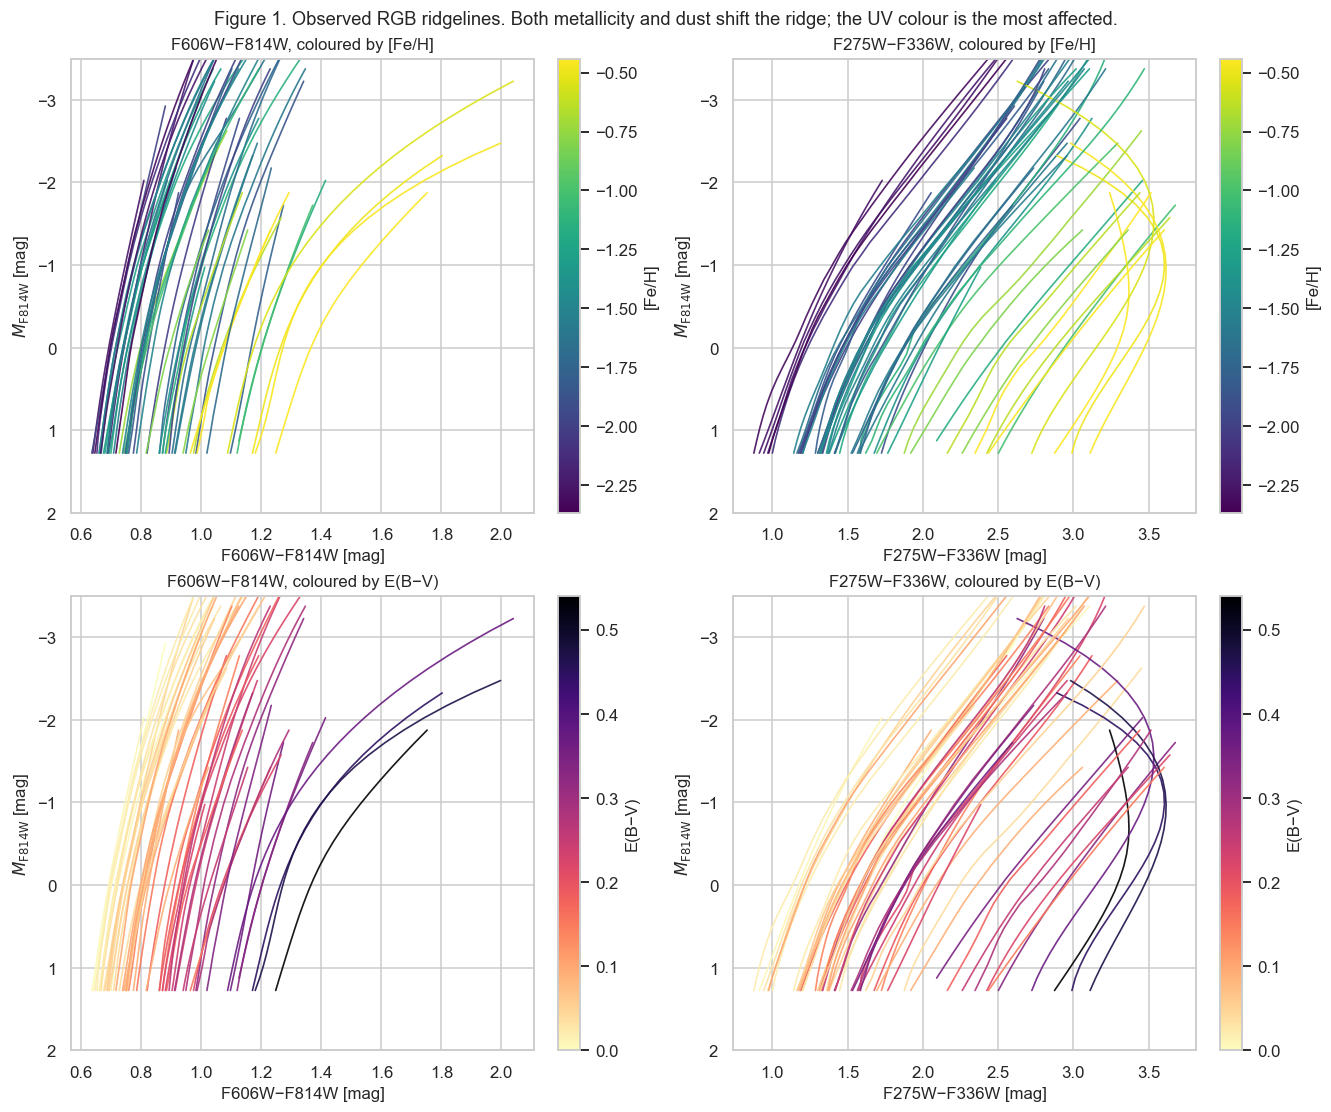

In [5]:
display(Markdown(f'''
* Clusters with a complete ridge on the grid $M_{{F814W}}\\in[{GRID.min():.2f},{GRID.max():.2f}]$: **{len(Y)}**
* Clusters with an age: **{has_age.sum()}**
* [Fe/H] range: {fv.min():.2f} to {fv.max():.2f}; E(B\u2212V) range: {ev.min():.2f} to {ev.max():.2f}
'''))

fig, axes = plt.subplots(2, 2, figsize=(12, 10), constrained_layout=True)
nf, ne = plt.Normalize(fv.min(), fv.max()), plt.Normalize(ev.min(), ev.max())
for col, c in enumerate(['F606W-F814W', 'F275W-F336W']):
    for row, (vals, norm, cmap, lab) in enumerate([(feh, nf, plt.cm.viridis, '[Fe/H]'), (ebv, ne, plt.cm.magma_r, 'E(B\u2212V)')]):
        ax = axes[row, col]
        for n in Y.index:
            d = ridges[n]
            ax.plot(d[c], d['F814W_abs'], color=cmap(norm(vals[n])), lw=1.1, alpha=0.9)
        ax.set_ylim(2.0, -3.5); ax.set_xlabel(nice(c) + ' [mag]'); ax.set_ylabel(MLAB)
        ax.set_title(f'{nice(c)}, coloured by {lab}')
        fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, label=lab)
fig.suptitle('Figure 1. Observed RGB ridgelines. Both metallicity and dust shift the ridge; the UV colour is the most affected.', fontsize=12)
plt.show()

**In plain words (Figure 1).** Each line is one cluster's red-giant track (brighter stars at the top). In the top row the lines are coloured by metallicity, bottom row by dust. Both rows show clear colour gradients, so *both* things shift where a cluster's track sits. The same few clusters that are the most metal-rich (yellow, top) are also among the dustiest (dark, bottom), which is exactly why the two effects are hard to separate. The left column is an optical colour and the right is an ultraviolet colour; the ultraviolet one spans a wider range and its tracks bend in more complicated ways, because dust blocks ultraviolet light the most.

## 3. Ridgelines are low-dimensional, and two physical drivers dominate

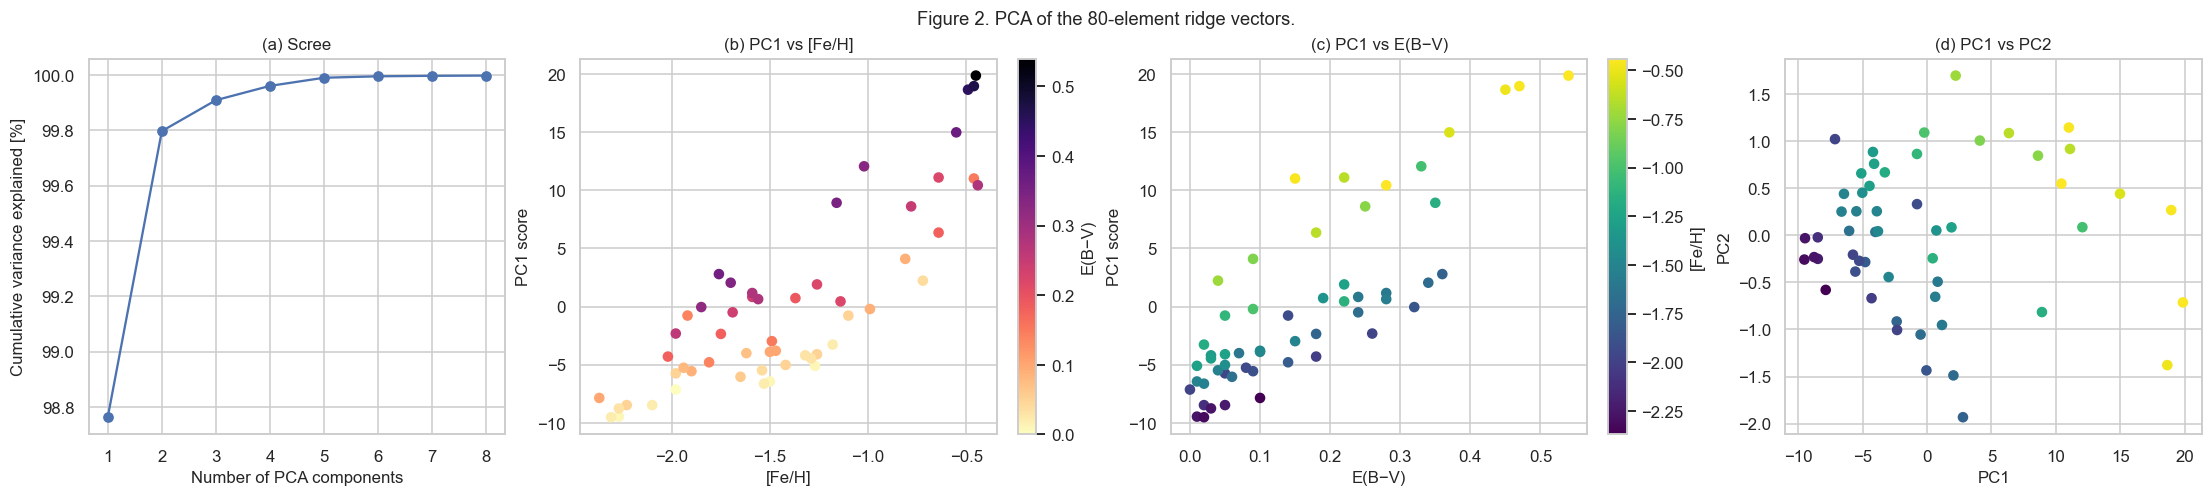

,variance [%],corr with [Fe/H],corr with E(B−V)
PC1,98.76,0.83,0.83
PC2,1.03,0.43,-0.51
PC3,0.11,0.06,0.06
PC4,0.05,0.01,-0.01


In [6]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.4), constrained_layout=True)
axes[0].plot(range(1, 9), cum_var[:8] * 100, marker='o')
axes[0].set_xlabel('Number of PCA components'); axes[0].set_ylabel('Cumulative variance explained [%]')
axes[0].set_title('(a) Scree')
sc = axes[1].scatter(fv, scores[:, 0], c=ev, cmap='magma_r', s=35)
axes[1].set_xlabel('[Fe/H]'); axes[1].set_ylabel('PC1 score'); axes[1].set_title('(b) PC1 vs [Fe/H]')
fig.colorbar(sc, ax=axes[1], label='E(B\u2212V)')
sc = axes[2].scatter(ev, scores[:, 0], c=fv, cmap='viridis', s=35)
axes[2].set_xlabel('E(B\u2212V)'); axes[2].set_ylabel('PC1 score'); axes[2].set_title('(c) PC1 vs E(B\u2212V)')
fig.colorbar(sc, ax=axes[2], label='[Fe/H]')
sc = axes[3].scatter(scores[:, 0], scores[:, 1], c=fv, cmap='viridis', s=35)
axes[3].set_xlabel('PC1'); axes[3].set_ylabel('PC2'); axes[3].set_title('(d) PC1 vs PC2')
fig.suptitle('Figure 2. PCA of the 80-element ridge vectors.', fontsize=12)
plt.show()
pd.DataFrame({'variance [%]': pca_full.explained_variance_ratio_[:4] * 100,
              'corr with [Fe/H]': [np.corrcoef(scores[:, j], fv)[0, 1] for j in range(4)],
              'corr with E(B\u2212V)': [np.corrcoef(scores[:, j], ev)[0, 1] for j in range(4)]},
             index=[f'PC{j+1}' for j in range(4)]).round(2)

**In plain words (Figure 2).** The 80 numbers per cluster behave like one or two dials (panel a). The main dial turns with metallicity *and* with dust (panels b, c), and the two are tangled together because metal-richer clusters in our sample also tend to be dustier. That is why we cannot ignore dust.

*Technical reading.* Panel (a): essentially all the structure is in the first two components. Panels (b, c): PC1 is a mixture of metallicity and reddening, and in this sample the two are partly correlated, so neither alone describes it. A model that ignores E(B−V) will therefore attribute dust effects to scatter.

## 4. Forward model

### 4.1 Which inputs are needed?

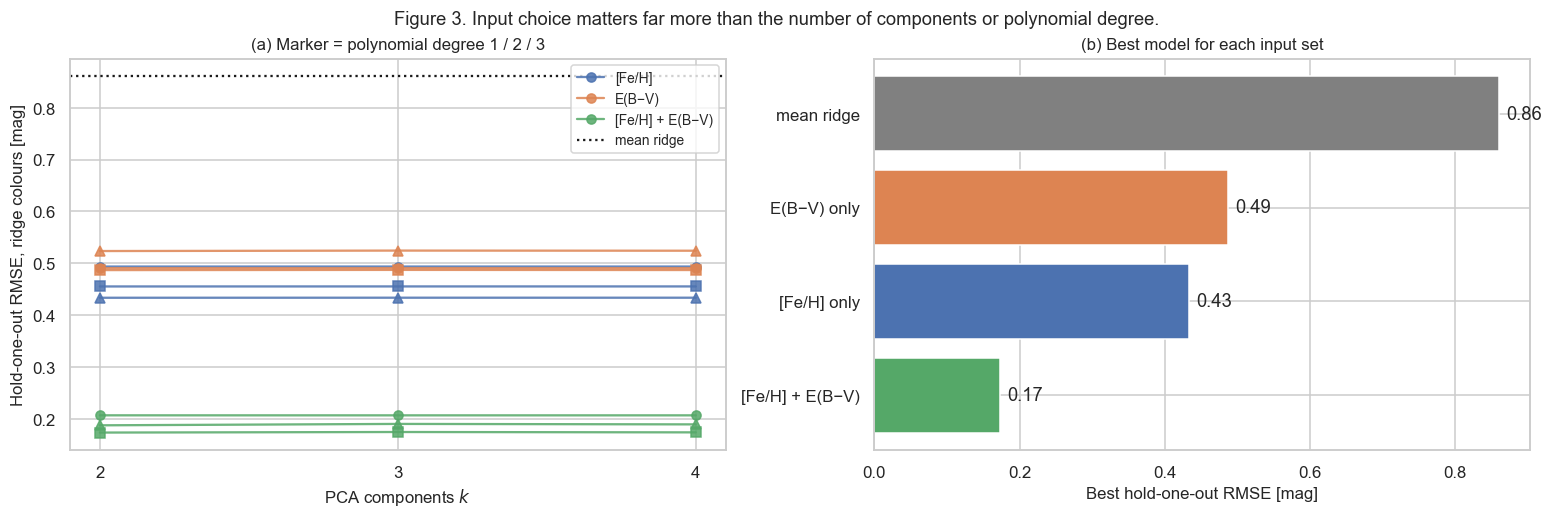

Selected model: **PCA2 + poly2** on ([Fe/H], E(B−V)), RMSE = 0.174 mag.

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), constrained_layout=True)
cols = {'[Fe/H]': 'C0', 'E(B\u2212V)': 'C1', '[Fe/H] + E(B\u2212V)': 'C2'}
for iname, c in cols.items():
    for deg, mk in zip([1, 2, 3], ['o', 's', '^']):
        ys = [res[(res.inputs == iname) & (res.model == f'PCA{k} + poly{deg}')].RMSE_mag.iloc[0] for k in [2, 3, 4]]
        axes[0].plot([2, 3, 4], ys, marker=mk, color=c, ls='-', alpha=0.85, label=iname if deg == 1 else None)
axes[0].axhline(RMSE['mean'], color='k', ls=':', label='mean ridge')
axes[0].set_xticks([2, 3, 4]); axes[0].set_xlabel('PCA components $k$'); axes[0].set_ylabel('Hold-one-out RMSE, ridge colours [mag]')
axes[0].legend(fontsize=9); axes[0].set_title('(a) Marker = polynomial degree 1 / 2 / 3')
labs = ['mean ridge', 'E(B\u2212V) only', '[Fe/H] only', '[Fe/H] + E(B\u2212V)']
vals = [RMSE['mean'], RMSE['ebv'], RMSE['fe'], RMSE['both']]
axes[1].barh(labs, vals, color=['gray', 'C1', 'C0', 'C2'])
for i, v in enumerate(vals): axes[1].text(v + 0.01, i, f'{v:.2f}', va='center')
axes[1].set_xlabel('Best hold-one-out RMSE [mag]'); axes[1].set_title('(b) Best model for each input set'); axes[1].invert_yaxis()
fig.suptitle('Figure 3. Input choice matters far more than the number of components or polynomial degree.', fontsize=12)
plt.show()
display(Markdown(f'Selected model: **{BEST_NAME}** on ([Fe/H], E(B\u2212V)), RMSE = {RMSE["both"]:.3f} mag.'))

**In plain words (Figure 3).** Shorter bars are better. Guessing the average fingerprint is wrong by about 0.9 mag. Using metallicity alone, or dust alone, roughly halves that. Using **both** cuts it to about a fifth. The number of dials and the complexity of the curve barely matter (panel a); what matters is telling the model about both metallicity and dust.

### 4.2 Fit quality on held-out clusters

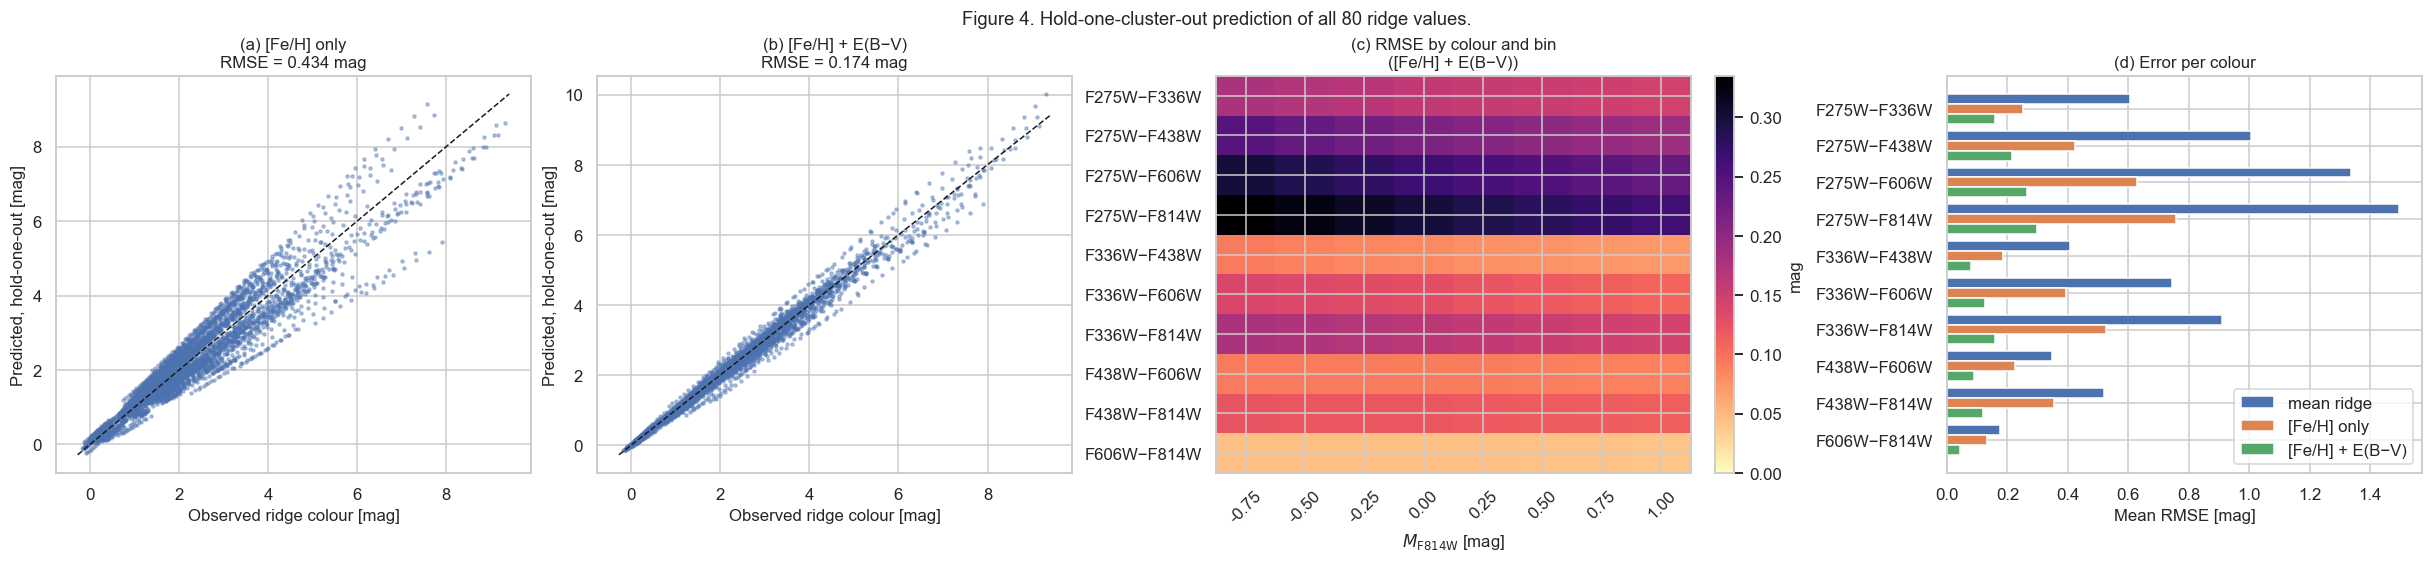

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(22, 5), constrained_layout=True)
lim = [Yv.min() - .1, Yv.max() + .1]
for ax, PP, t in [(axes[0], P_fe, '(a) [Fe/H] only'), (axes[1], P_best, '(b) [Fe/H] + E(B\u2212V)')]:
    ax.scatter(Yv.ravel(), PP.ravel(), s=4, alpha=0.4)
    ax.plot(lim, lim, 'k--', lw=1)
    ax.set_xlabel('Observed ridge colour [mag]'); ax.set_ylabel('Predicted, hold-one-out [mag]')
    ax.set_title(f'{t}\nRMSE = {rmse(PP, Yv):.3f} mag')
res_map = np.sqrt(((P_best - Yv) ** 2).mean(0)).reshape(len(COLORS), len(GRID))
im = axes[2].imshow(res_map, aspect='auto', cmap='magma_r', vmin=0)
axes[2].set_xticks(range(len(GRID))); axes[2].set_xticklabels([f'{g:.2f}' for g in GRID], rotation=45)
axes[2].set_yticks(range(len(COLORS))); axes[2].set_yticklabels([nice(c) for c in COLORS])
axes[2].set_xlabel(MLAB); axes[2].set_title('(c) RMSE by colour and bin\n([Fe/H] + E(B\u2212V))')
fig.colorbar(im, ax=axes[2], label='mag')
yy = np.arange(len(COLORS))
axes[3].barh(yy - 0.27, np.sqrt(((baseline - Yv) ** 2).mean(0)).reshape(len(COLORS), len(GRID)).mean(1), 0.27, label='mean ridge')
axes[3].barh(yy, np.sqrt(((P_fe - Yv) ** 2).mean(0)).reshape(len(COLORS), len(GRID)).mean(1), 0.27, label='[Fe/H] only')
axes[3].barh(yy + 0.27, res_map.mean(1), 0.27, label='[Fe/H] + E(B\u2212V)')
axes[3].set_yticks(yy); axes[3].set_yticklabels([nice(c) for c in COLORS]); axes[3].invert_yaxis()
axes[3].set_xlabel('Mean RMSE [mag]'); axes[3].legend(); axes[3].set_title('(d) Error per colour')
fig.suptitle('Figure 4. Hold-one-cluster-out prediction of all 80 ridge values.', fontsize=12)
plt.show()

**In plain words (Figure 4).** Panels (a, b): each dot is one colour at one brightness for one cluster. Perfect predictions would lie on the dashed line. With metallicity alone (a) the dots are scattered widely; adding dust (b) pulls them onto the line. Panels (c, d): the biggest errors are in the colours that span from ultraviolet to infrared, because those are the most affected by dust. The optical colour F606W−F814W is predicted almost perfectly.

*Technical reading.* Adding E(B−V) tightens the parity relation (a→b). Errors scale with the colour baseline (panel c, d): the wide UV-to-optical colours, which are the most reddening-sensitive, carry the largest absolute errors, while F606W−F814W is predicted to ~0.1 mag.

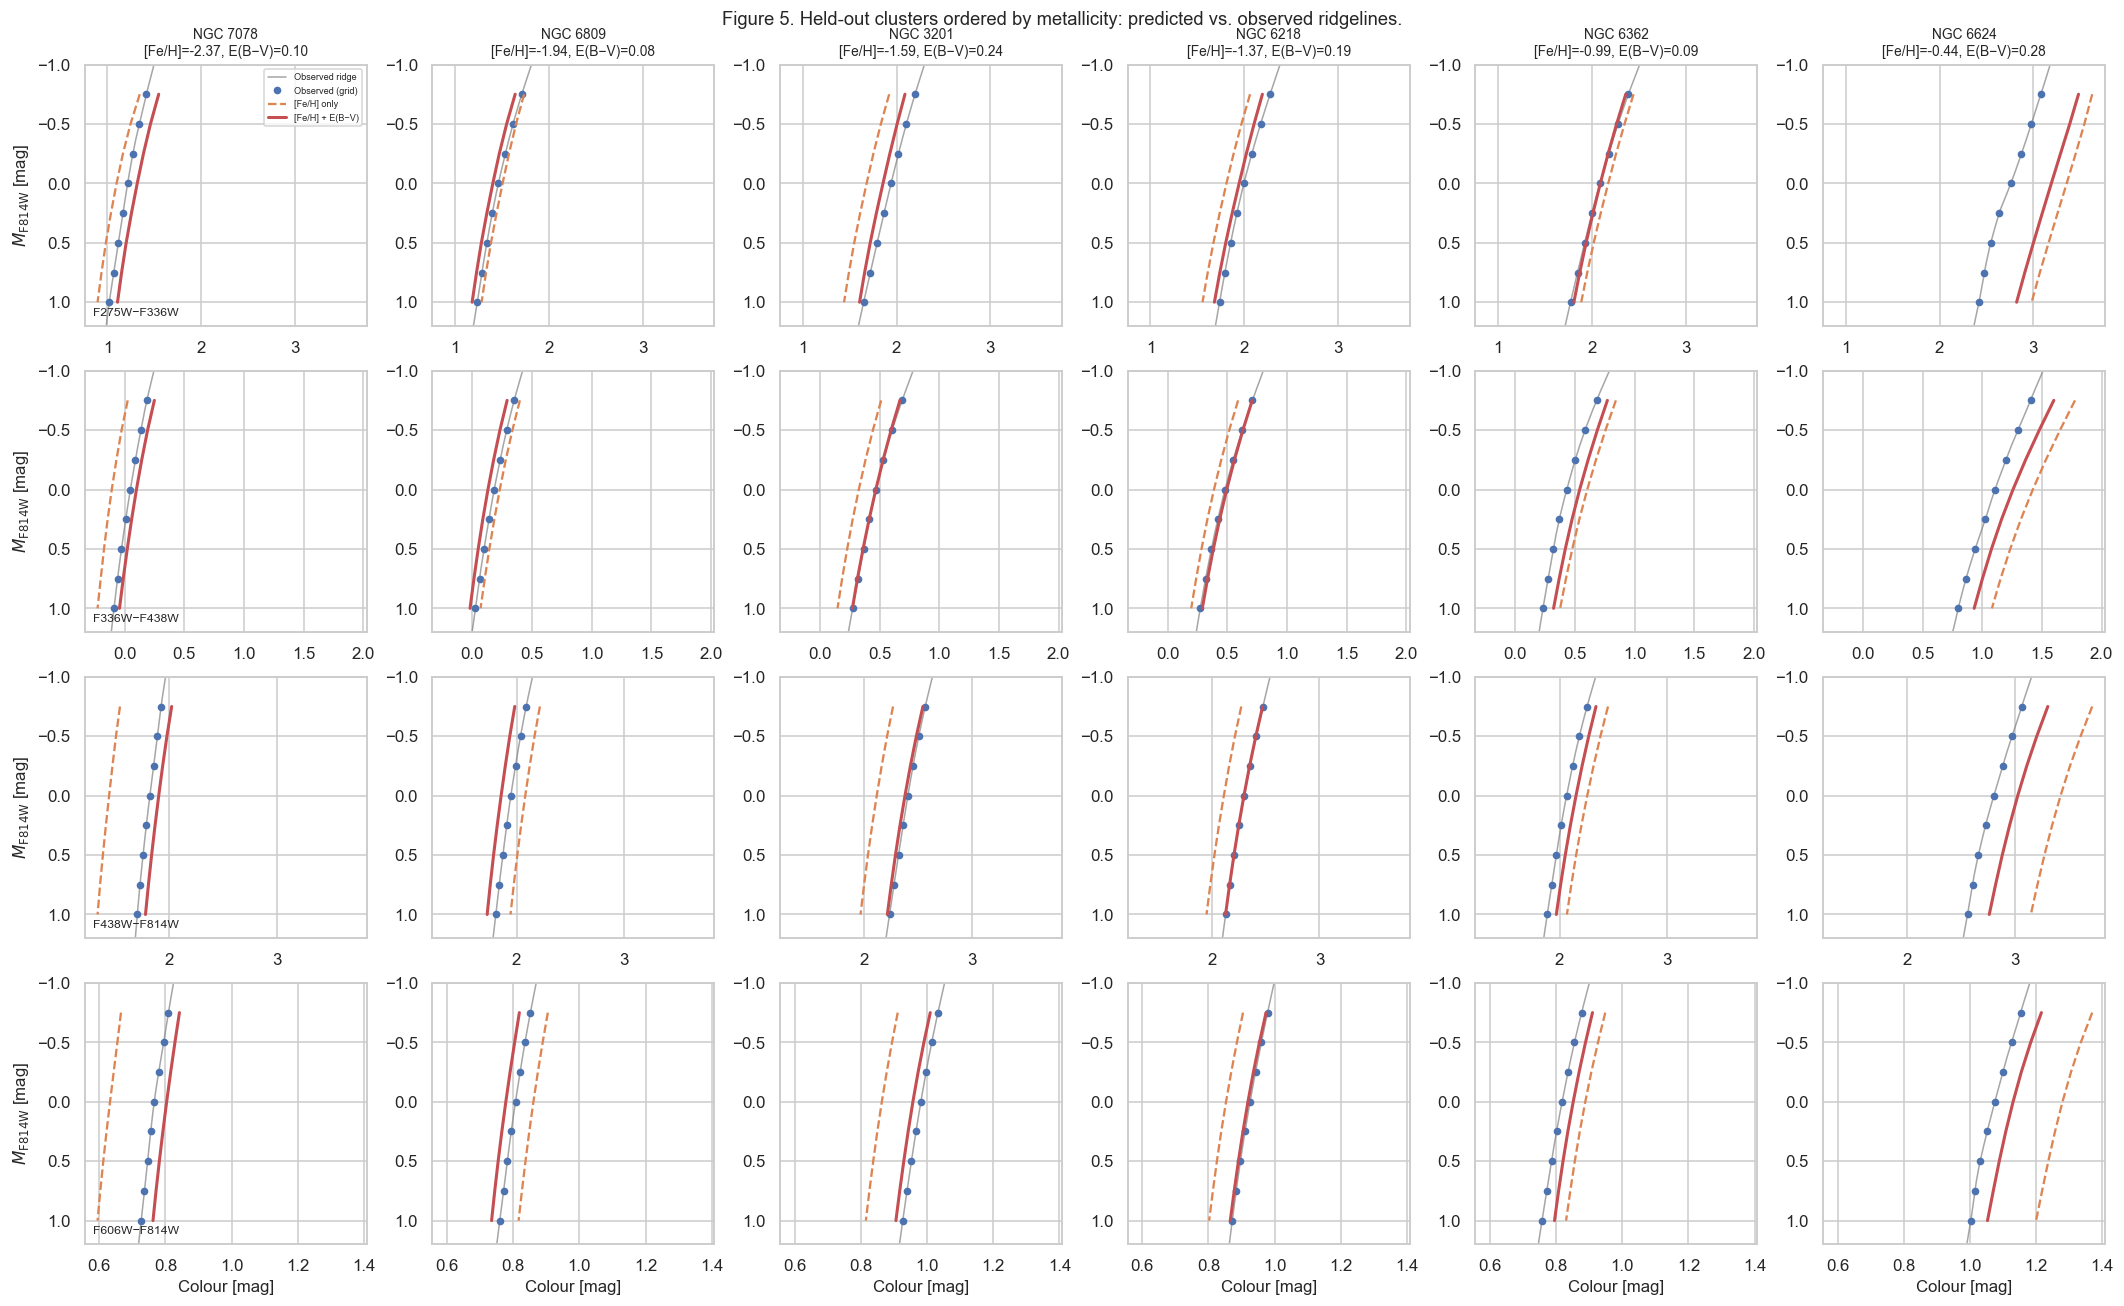

In [9]:
order = np.argsort(fv)
pick = order[np.linspace(0, len(order) - 1, 6).astype(int)]
fig, axes = plt.subplots(len(SHOW), len(pick), figsize=(3.2 * len(pick), 2.9 * len(SHOW)), sharex='row', constrained_layout=True)
for j, i in enumerate(pick):
    for r, c in enumerate(SHOW):
        ci = COLORS.index(c); sl = slice(ci * len(GRID), (ci + 1) * len(GRID))
        ax = axes[r, j]
        full = ridges[Y.index[i]]
        ax.plot(full[c], full['F814W_abs'], color='gray', lw=1, alpha=0.7, label='Observed ridge')
        ax.plot(Yv[i, sl], GRID, 'o', color='C0', ms=4, label='Observed (grid)')
        ax.plot(P_fe[i, sl], GRID, '--', color='C1', lw=1.5, label='[Fe/H] only')
        ax.plot(P_best[i, sl], GRID, '-', color='C3', lw=2, label='[Fe/H] + E(B\u2212V)')
        ax.set_ylim(1.2, -1.0)
        if r == 0: ax.set_title(f'NGC {Y.index[i]}\n[Fe/H]={fv[i]:.2f}, E(B\u2212V)={ev[i]:.2f}', fontsize=9)
        if j == 0: ax.set_ylabel(MLAB); ax.text(0.03, 0.04, nice(c), transform=ax.transAxes, fontsize=8)
        if r == len(SHOW) - 1: ax.set_xlabel('Colour [mag]')
axes[0, 0].legend(fontsize=6, loc='upper right')
fig.suptitle('Figure 5. Held-out clusters ordered by metallicity: predicted vs. observed ridgelines.', fontsize=12, y=1.01)
plt.show()

**In plain words (Figure 5).** Each column is a different cluster, from metal-poor (left) to metal-rich (right). The grey line is the real track, the blue dots are the points we compare with, the dashed orange line is what a metallicity-only model predicts, and the solid red line is what the metallicity + dust model predicts. The red line sits on the real track; the orange line is shifted away. None of these clusters were used to train the prediction.

*Technical reading.* Each cluster was excluded from the fit. The [Fe/H]-only model (dashed) is offset systematically, in a direction set by the cluster's dust. With E(B−V) (solid) the prediction follows the observed ridge in both position and slope. The weakest case is the metal-rich edge of the sample (e.g. NGC 6624), where there are few training clusters.

### 4.3 The model as an emulator

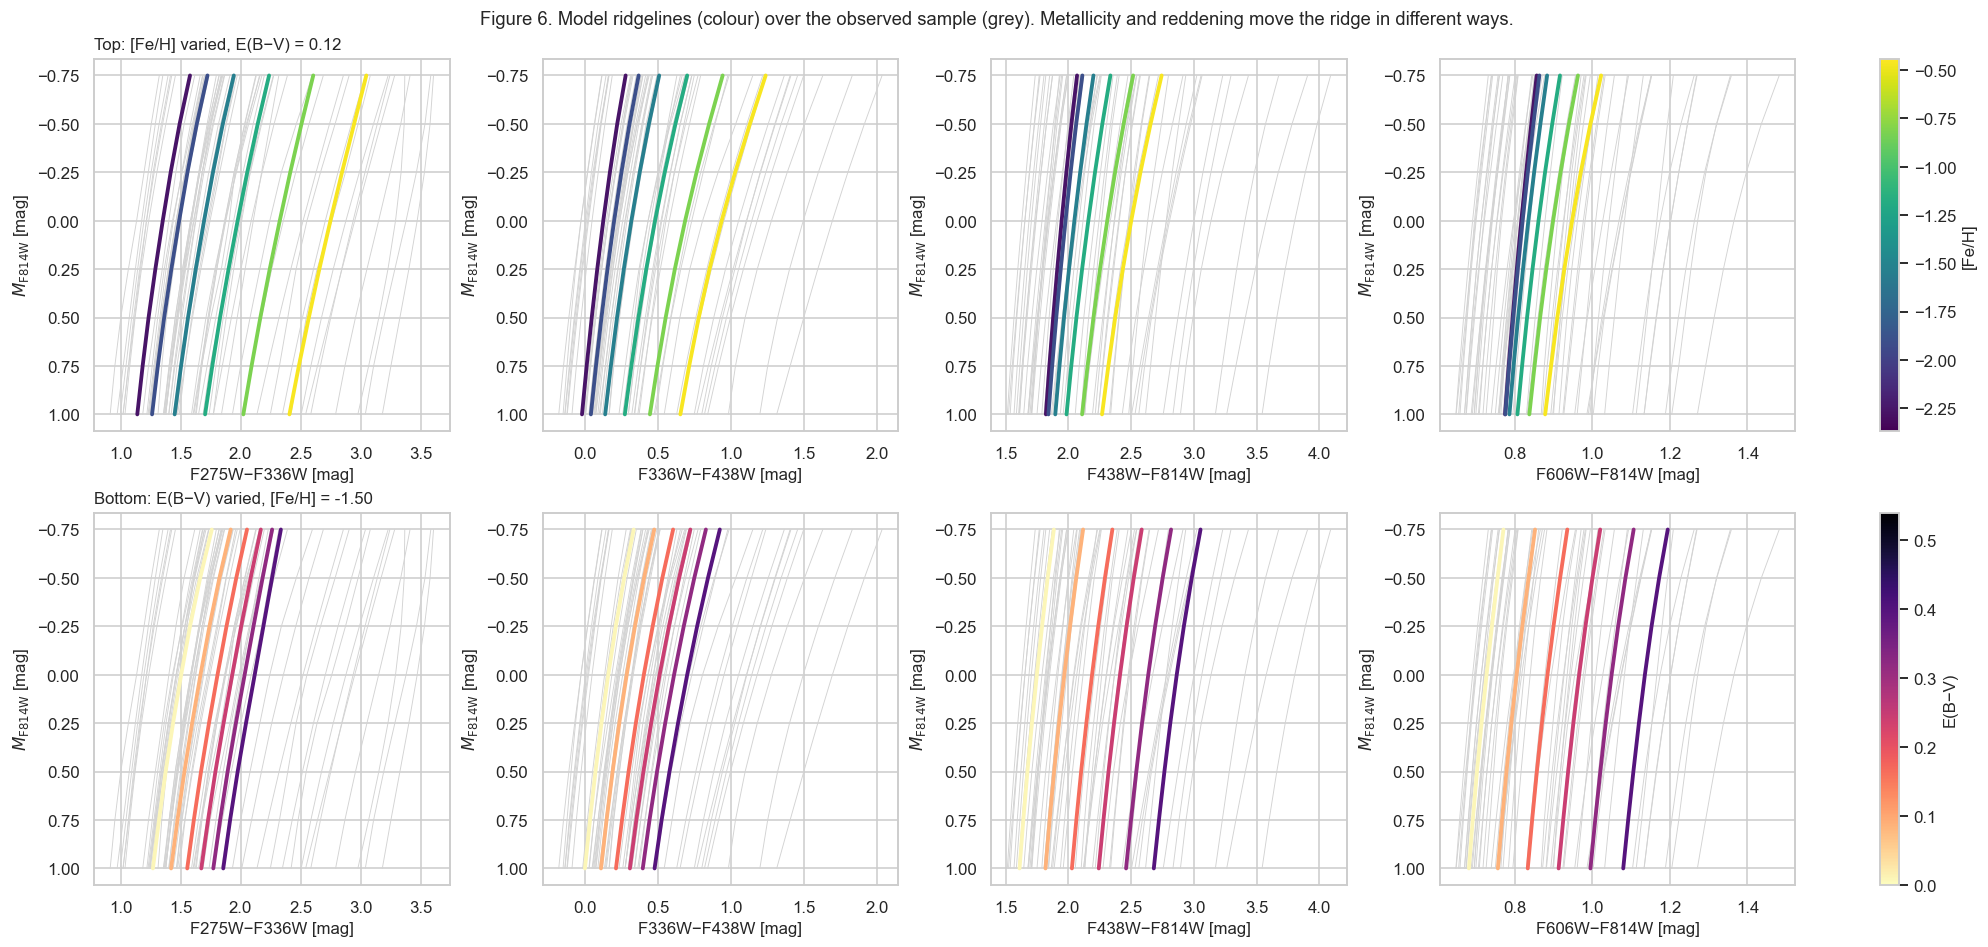

In [10]:
final = ForwardModel(K_BEST, DEG_BEST).fit(INPUTS[BEST_IN], Yv)
fe_sw = np.linspace(np.percentile(fv, 5), np.percentile(fv, 95), 6)
eb_sw = np.linspace(np.percentile(ev, 5), np.percentile(ev, 95), 6)
S1 = final.predict(np.c_[fe_sw, np.full_like(fe_sw, np.median(ev))])
S2 = final.predict(np.c_[np.full_like(eb_sw, np.median(fv)), eb_sw])
fig, axes = plt.subplots(2, 4, figsize=(18, 8.5), constrained_layout=True)
for r, (S, sw, lab, cmap, rng) in enumerate([(S1, fe_sw, '[Fe/H]', plt.cm.viridis, (fv.min(), fv.max())), (S2, eb_sw, 'E(B\u2212V)', plt.cm.magma_r, (ev.min(), ev.max()))]):
    norm = plt.Normalize(*rng)
    for ax, c in zip(axes[r], SHOW):
        ci = COLORS.index(c); sl = slice(ci * len(GRID), (ci + 1) * len(GRID))
        for i in range(len(Yv)): ax.plot(Yv[i, sl], GRID, color='lightgray', lw=0.6)
        for s, row in zip(sw, S): ax.plot(row[sl], GRID, color=cmap(norm(s)), lw=2.5)
        ax.invert_yaxis(); ax.set_xlabel(nice(c) + ' [mag]'); ax.set_ylabel(MLAB)
    fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=axes[r], label=lab)
axes[0, 0].set_title(f'Top: [Fe/H] varied, E(B\u2212V) = {np.median(ev):.2f}', loc='left')
axes[1, 0].set_title(f'Bottom: E(B\u2212V) varied, [Fe/H] = {np.median(fv):.2f}', loc='left')
fig.suptitle('Figure 6. Model ridgelines (colour) over the observed sample (grey). Metallicity and reddening move the ridge in different ways.', fontsize=12)
plt.show()

**In plain words (Figure 6).** This is the model used as a "what if" machine. Top row: keep the dust fixed and make the cluster more metal-rich, and the track moves one way. Bottom row: keep the metallicity fixed and add dust, and the track shifts to redder colours, much more in the ultraviolet. Because the two effects look different, the model can tell them apart.

*Technical reading.* Varying [Fe/H] mostly changes the colour and slope of the ridge in a way that depends on colour pair, while varying E(B−V) produces a near-rigid shift whose amplitude grows toward the UV. This is what allows the two to be separated.

### 4.4 Does age carry additional information?

Only a subset of clusters has an age, so this is a lower-powered test.

,inputs,RMSE_mag,model
0,[Fe/H] + E(B−V) + age,0.131,PCA2 + poly2
1,[Fe/H] + E(B−V) + age,0.132,PCA3 + poly2
2,[Fe/H] + E(B−V),0.142,PCA2 + poly2
3,[Fe/H] + E(B−V),0.143,PCA3 + poly2
4,[Fe/H] + E(B−V) + age,0.158,PCA2 + poly1
5,[Fe/H] + E(B−V),0.188,PCA2 + poly1
6,mean ridge,0.655,NaN


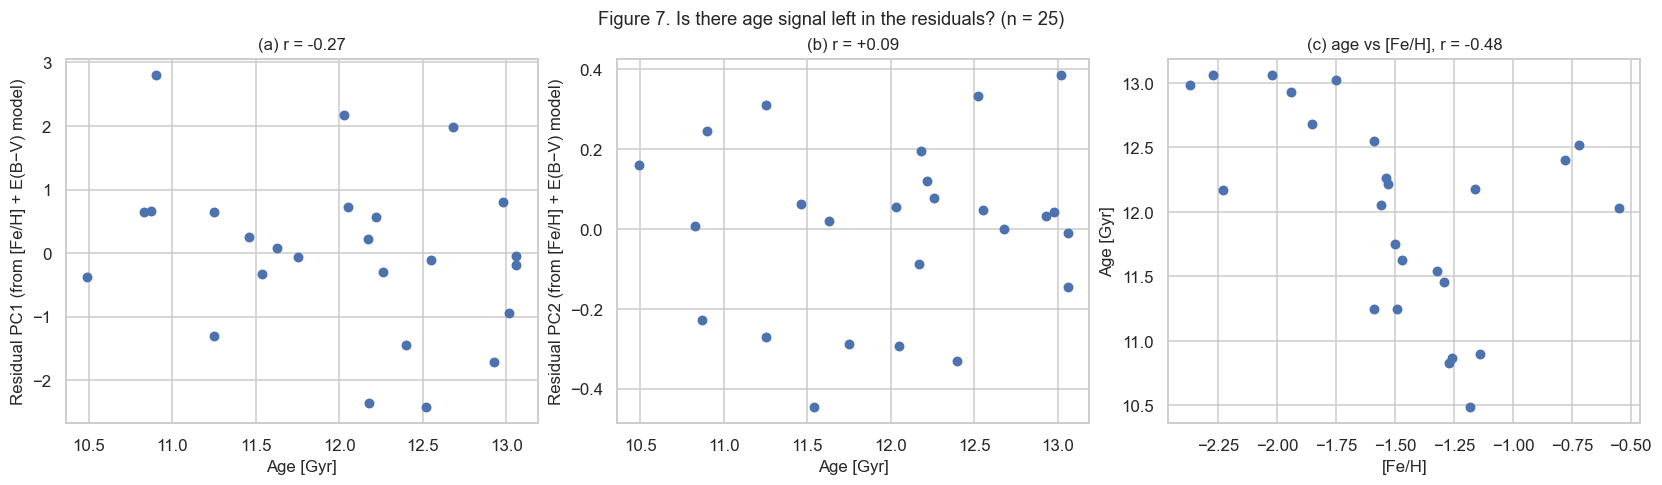

In [11]:
display(age_res.sort_values('RMSE_mag').round(3).reset_index(drop=True))
key = ('[Fe/H] + E(B\u2212V)', 'PCA3 + poly2')
resid_sub = age_preds[key] - Ys
sc2 = PCA(n_components=2).fit_transform(resid_sub)
a_ = av[has_age]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), constrained_layout=True)
for j, ax in enumerate(axes[:2]):
    ax.scatter(a_, sc2[:, j], s=30)
    ax.set_xlabel('Age [Gyr]'); ax.set_ylabel(f'Residual PC{j+1} (from [Fe/H] + E(B\u2212V) model)')
    ax.set_title(f'({"ab"[j]}) r = {np.corrcoef(a_, sc2[:, j])[0,1]:+.2f}')
axes[2].scatter(fv[has_age], a_, s=30); axes[2].set_xlabel('[Fe/H]'); axes[2].set_ylabel('Age [Gyr]')
axes[2].set_title(f'(c) age vs [Fe/H], r = {np.corrcoef(fv[has_age], a_)[0,1]:+.2f}')
fig.suptitle(f'Figure 7. Is there age signal left in the residuals? (n = {has_age.sum()})', fontsize=12)
plt.show()

**In plain words (Figure 7).** Age might also change the fingerprint. We tested whether what the model *gets wrong* lines up with age. It barely does, and we only know ages for about half the clusters, so we cannot say yet whether age leaves a measurable mark.

*Technical reading.* Adding age lowers the error slightly (table above), but the residual PCs show no clean trend with age and the sample is small and narrow in age. We cannot claim an age constraint from this data.

## 5. Inverting the forward model to estimate [Fe/H]

For each held-out cluster, with the forward model fit to the other clusters, we search for the [Fe/H] whose predicted ridge (at the cluster's catalogued E(B−V)) minimises a $\chi^2$ against the observed ridge, with each ridge value weighted by the model's training scatter. Error bars are a crude $\Delta\chi^2$ interval, inflated by the reduced $\chi^2$. For comparison, direct regressors (ridge, RBF-SVR) map the same 80 ridge values straight to [Fe/H] **without** being told E(B−V).

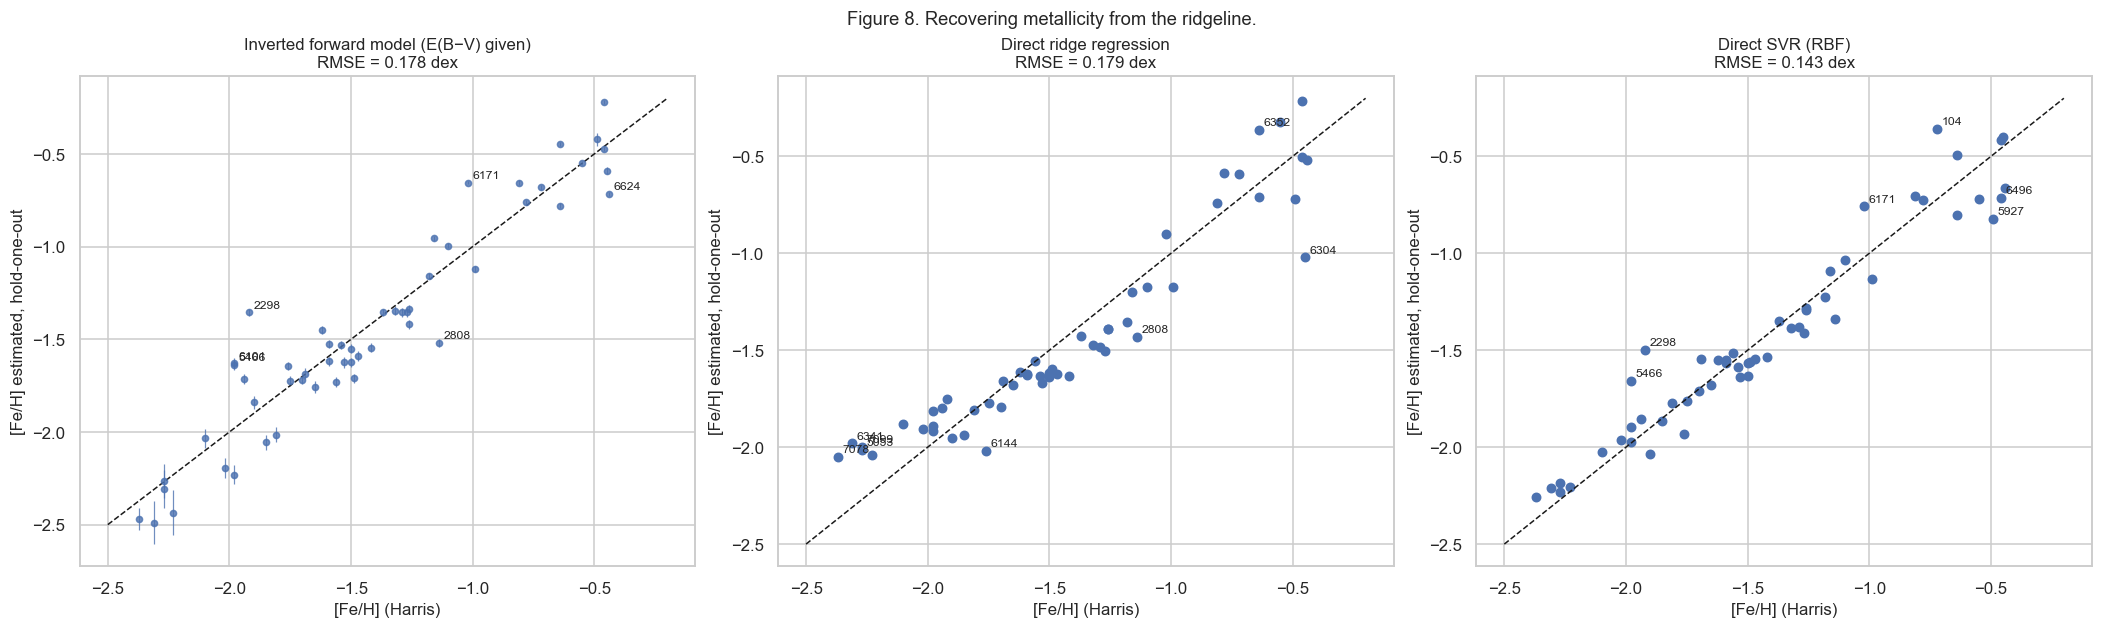

,RMSE [dex],"corr(residual, E(B−V))"
Predict the mean,0.542,0.457
Inverted forward model (E(B−V) given),0.178,-0.041
Direct ridge regression,0.179,-0.189
Direct SVR (RBF),0.143,-0.118


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.6), constrained_layout=True)
for ax, (t, p), e in zip(axes, estimators.items(), [inv_sd, None, None]):
    if e is not None: ax.errorbar(fv, p, yerr=e, fmt='o', ms=4, lw=0.8, alpha=0.8)
    else: ax.scatter(fv, p, s=30)
    ax.plot([-2.5, -0.2], [-2.5, -0.2], 'k--', lw=1)
    for n, a, b in zip(Y.index, fv, p):
        if abs(a - b) > 0.25: ax.annotate(str(n), (a, b), fontsize=8, xytext=(3, 3), textcoords='offset points')
    ax.set_xlabel('[Fe/H] (Harris)'); ax.set_ylabel('[Fe/H] estimated, hold-one-out')
    ax.set_title(f'{t}\nRMSE = {rmse(p, fv):.3f} dex')
fig.suptitle('Figure 8. Recovering metallicity from the ridgeline.', fontsize=12)
plt.show()

tab = pd.DataFrame({'RMSE [dex]': {'Predict the mean': inv_rmse_mean, **inv_rmse},
                    'corr(residual, E(B\u2212V))': {'Predict the mean': np.corrcoef(fv - fv.mean(), ev)[0, 1],
                                                 **{k: np.corrcoef(v - fv, ev)[0, 1] for k, v in estimators.items()}}})
tab.round(3)

**In plain words (Figure 8).** Now we go backwards: given only the fingerprint, how well can we recover the metallicity? Dots on the dashed line are perfect. All three methods do far better than just guessing the average (see the table). We also checked that the methods are not secretly using dust as a shortcut for metallicity: the last column of the table, which shows whether the errors line up with dust, is close to zero.

*Technical reading.* All three estimators beat the no-information baseline by a wide margin. The direct SVR has the lowest error in this notebook; the inverted physical model matches the linear regression and, unlike either, supplies a per-cluster uncertainty and a way to propagate E(B−V). The last column checks the confounding worry: the residuals of the direct regressors are only weakly correlated with E(B−V), so they are not using dust as a proxy for metallicity.

## 6. Caveats

**In plain words:** we have only 54 clusters, the "true" metallicities themselves are uncertain by about 0.1 dex, and we assumed a single dust value per cluster. So treat small differences between methods as ties, and the results as a promising first step, not a final answer.

* **Small sample.** 54 clusters; the polynomial and PCA settings were chosen from a small grid on the same data. Treat differences of ~0.02 mag / ~0.02 dex as ties. A fully nested selection was run separately for the direct regressors and is not part of this notebook.
* **Label noise.** Harris [Fe/H] carries ~0.1 dex scale uncertainty; this sets a floor on any [Fe/H] RMSE.
* **Reddening.** E(B−V) is a catalogue value (single number, fixed law). Differential reddening and variations in $R_V$ are not modelled; the residual structure in the UV colours is consistent with this.
* **Edge of the sample.** The most metal-rich clusters (e.g. NGC 6624) are the worst predicted.
* **Ages** are available for a subset only and span a narrow range, so any age signal is weak.
* Catalogue values were retrieved programmatically and spot-checked against known clusters and the spectroscopic medians; they have not been verified line by line against the source files.

## 7. Next steps

1. Fit E(B−V) as a free parameter in the inversion (and ideally $R_V$), rather than fixing it from a catalogue.
2. Compare the emulator with theoretical isochrones (MIST, Dartmouth) at the same [Fe/H], age, distance and reddening.
3. Add the $M_{F438W}$-axis ridges for fainter and brighter parts of the RGB.
4. Use out-of-fold predicted [Fe/H] as an input to the Na/Fe regression.